In [ ]:
from builder import loadSpec, newGraph
from output import getTriples
from classes import node, person, relation

spec_path = "../testGraph1.yml"

In [2]:
people = loadSpec(spec_path)

In [3]:
sibling_of = relation('is the sibling of')
child_of = relation('is the child of')
spouse_of = relation('is the spouse of')
parent_of = relation('is the parent of')

sibling_of.specify(person, person, recip=[sibling_of], share=[sibling_of, child_of], no=[spouse_of], max=4, gen=0)
parent_of.specify(person, person, recip=[child_of], onehop=[(sibling_of, parent_of), (child_of, spouse_of)], max = 5, gen = 1)
child_of.specify(person, person, recip=[parent_of], onehop=[(spouse_of, child_of), (parent_of, sibling_of)], max = 2, gen = -1)
spouse_of.specify(person, person, recip=[spouse_of], share=[parent_of], no=[sibling_of, parent_of, child_of], max=1, gen=0)

relations = [sibling_of, child_of, spouse_of, parent_of]

In [9]:
graph = newGraph(people, relations, 5)

Bob
is the sibling of
Philip
Generational mismatch
Bob
is the sibling of
Tagora
Call to checkShare for relation is the sibling of between Bob and Tagora
Call to checkRecip for relation is the sibling of between Bob and Tagora
Call to checkShare for relation is the sibling of between Tagora and Bob
Call to checkShare for relation is the sibling of between Tagora and Ariela
Call to checkRecip for relation is the sibling of between Tagora and Ariela
Call to checkShare for relation is the sibling of between Ariela and Tagora
Checking reciprocal’s onehop.
Call to checkOneHop for relation is the sibling of between Ariela and Tagora
Call to checkOneHop for relation is the sibling of between Tagora and Ariela
Checking reciprocal’s onehop.
Call to checkOneHop for relation is the sibling of between Tagora and Bob
Call to checkOneHop for relation is the sibling of between Bob and Tagora
Bob is the sibling of Tagora
Tagora is the sibling of Bob
Tagora is the sibling of Ariela
Ariela is the sibling

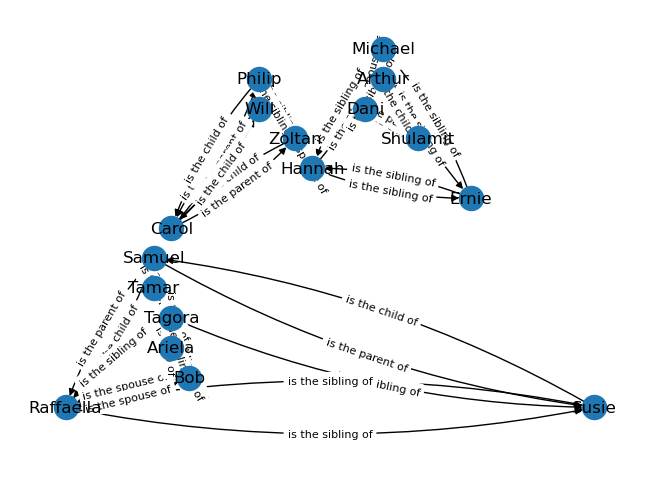

In [10]:
persons = []
for person in people:
    if bool(person.getAllRels()) is not False:
        persons.append(person)

printGraph(persons)

In [11]:
getTriples(persons)

Bob is the spouse of Raffaella.
Bob is the sibling of Ariela.
Bob is the sibling of Tagora.
Raffaella is the spouse of Bob.
Raffaella is the sibling of Susie.
Raffaella is the child of Samuel.
Dani is the sibling of Arthur.
Dani is the child of Shulamit.
Dani is the spouse of Michael.
Hannah is the sibling of Michael.
Hannah is the sibling of Ernie.
Hannah is the spouse of Zoltan.
Zoltan is the child of Carol.
Zoltan is the spouse of Hannah.
Zoltan is the sibling of Philip.
Tamar is the spouse of Tagora.
Will is the parent of Carol.
Samuel is the parent of Raffaella.
Samuel is the parent of Susie.
Samuel is the parent of Tagora.
Shulamit is the parent of Dani.
Shulamit is the parent of Arthur.
Michael is the sibling of Ernie.
Michael is the sibling of Hannah.
Michael is the spouse of Dani.
Ariela is the sibling of Bob.
Ariela is the sibling of Tagora.
Arthur is the sibling of Dani.
Arthur is the child of Shulamit.
Carol is the parent of Zoltan.
Carol is the parent of Philip.
Carol is t

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

def printGraph(nodes) -> None:
    testgraph = nx.MultiDiGraph()
    testgraph.add_nodes_from(nodes)
    for person in nodes:
        testgraph.add_edges_from(person.getAllRels())
    edge_labels = nx.get_edge_attributes(testgraph, "Rel")
    try:
        pos = nx.planar_layout(testgraph, 3)
        nx.draw(testgraph, pos, labels={person:person.getProp('Name') for person in nodes}, connectionstyle='arc3, rad = 0.1')
        nx.draw_networkx_edge_labels(testgraph, pos=pos, edge_labels=edge_labels, connectionstyle='arc3, rad = 0.1', font_size=8)
        plt.show()
    except:
        pos=nx.spectral_layout(testgraph)
        nx.draw(testgraph, pos, labels={person:person.getProp('Name') for person in nodes}, connectionstyle='arc3, rad = 0.1')
        nx.draw_networkx_edge_labels(testgraph, pos=pos, edge_labels=edge_labels, connectionstyle='arc3, rad = 0.1', font_size=8)
        plt.show()
    return None